# Phần Mạnh (2/2) — Khám Phá Dữ Liệu (EDA) và Tiền Xử Lý Luồng A

**Mục tiêu của notebook:**
1. **Khám phá và phân tích dữ liệu (EDA) trên tập Train:**
   - Quan sát phân phối của biến mục tiêu `Churn` (phát hiện và đánh giá mức độ mất cân bằng dữ liệu).
   - Phân tích mối quan hệ giữa các biến định tính (Hợp đồng, Dịch vụ Internet, Phương thức thanh toán, Dịch vụ bảo vệ...) với khả năng rời mạng của khách hàng.
   - Phân tích mối quan hệ giữa các biến định lượng (`tenure`, `MonthlyCharges`, `TotalCharges`) với `Churn` thông qua trung vị và biểu đồ mật độ.
   - *Nguyên tắc bảo vệ dữ liệu:* Toàn bộ bước EDA chỉ thực hiện độc lập trên tập **Train (5.634 mẫu)** nhằm ngăn chặn việc rò rỉ thông tin từ tập Test.
2. **Xây dựng Pipeline Tiền xử lý Luồng A (Pipeline cơ bản):**
   - Xử lý dữ liệu thiếu: Cột số dùng trung vị (`median`), cột phân loại dùng giá trị phổ biến nhất (`most_frequent`).
   - Chuẩn hóa đặc trưng số bằng `StandardScaler` (rất quan trọng đối với thuật toán K-NN).
   - Mã hóa đặc trưng phân loại bằng `OneHotEncoder(handle_unknown='ignore')`.
   - Kết hợp hoàn chỉnh qua `ColumnTransformer` (xuất ra 45 đặc trưng).
   - Áp dụng nguyên tắc `fit_transform` trên Train và chỉ `transform` trên Test.
   - Lưu trữ `X_train_A.csv`, `X_test_A.csv` và mô hình tiền xử lý `preprocessor_A.pkl`.

## 1. Thiết lập môi trường và nạp dữ liệu Train/Test cố định
Đọc lại các tập dữ liệu Train/Test đã chia từ notebook 01 (`X_train_raw.csv`, `X_test_raw.csv`, `y_train.csv`, `y_test.csv`). Tuyệt đối không chia lại dữ liệu để đảm bảo tính đồng bộ cho toàn bộ dự án.

In [1]:
from pathlib import Path
import sys
import pandas as pd

PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "src" / "config.py").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

assert (PROJECT_ROOT / "src" / "config.py").exists()
sys.path.insert(0, str(PROJECT_ROOT))

from src.config import TARGET_COLUMN

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"

print("Thư mục dữ liệu:", PROCESSED_DIR)
print("Cột mục tiêu:", TARGET_COLUMN)
print(
    "Có X_train_raw.csv?",
    (PROCESSED_DIR / "X_train_raw.csv").exists(),
)

Thư mục dữ liệu: C:\Users\admin\Desktop\Subject\Nhap_Mon_Hoc_May\BTL\BTL_New_Version\BTL_Nhap_Mon_Hoc_May_NHOM4\data\processed
Cột mục tiêu: Churn
Có X_train_raw.csv? True


In [2]:
X_train = pd.read_csv(PROCESSED_DIR / "X_train_raw.csv")
X_test = pd.read_csv(PROCESSED_DIR / "X_test_raw.csv")
y_train = pd.read_csv(PROCESSED_DIR / "y_train.csv")[TARGET_COLUMN]
y_test = pd.read_csv(PROCESSED_DIR / "y_test.csv")[TARGET_COLUMN]

assert len(X_train) == len(y_train)
assert len(X_test) == len(y_test)
assert X_train.columns.equals(X_test.columns)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (5634, 19)
X_test: (1409, 19)
y_train: (5634,)
y_test: (1409,)


## 2. Khám phá và phân tích dữ liệu trên tập Train (EDA)
Ghép $X_{train}$ và $y_{train}$ thành bảng tạm `df` để thực hiện khám phá dữ liệu. Kiểm tra kích thước, kiểu dữ liệu, các giá trị thiếu và tính duy nhất của dữ liệu.

In [3]:
df = X_train.copy()
df[TARGET_COLUMN] = y_train

display(df.head())
print("Kích thước bảng EDA:", df.shape)

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Male,0,No,No,35,No,No phone service,DSL,No,No,Yes,No,Yes,Yes,Month-to-month,No,Electronic check,49.20,1701.65,No
1,Male,0,Yes,Yes,15,Yes,No,Fiber optic,Yes,No,No,No,No,No,Month-to-month,No,Mailed check,75.10,1151.55,No
2,Male,0,Yes,Yes,13,No,No phone service,DSL,Yes,Yes,No,Yes,No,No,Two year,No,Mailed check,40.55,590.35,No
3,Female,0,Yes,No,26,Yes,No,DSL,No,Yes,Yes,No,Yes,Yes,Two year,Yes,Credit card (automatic),73.50,1905.70,No
4,Male,0,Yes,Yes,1,Yes,No,DSL,No,No,No,No,No,No,Month-to-month,No,Electronic check,44.55,44.55,No


Kích thước bảng EDA: (5634, 20)


In [4]:
df.info()

missing = df.isna().sum()
print("Các cột có giá trị thiếu:")
display(missing[missing > 0])

print("Số dòng trùng lặp trong Train:", df.duplicated().sum())

<class 'pandas.DataFrame'>
RangeIndex: 5634 entries, 0 to 5633
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   gender            5634 non-null   str    
 1   SeniorCitizen     5634 non-null   int64  
 2   Partner           5634 non-null   str    
 3   Dependents        5634 non-null   str    
 4   tenure            5634 non-null   int64  
 5   PhoneService      5634 non-null   str    
 6   MultipleLines     5634 non-null   str    
 7   InternetService   5634 non-null   str    
 8   OnlineSecurity    5634 non-null   str    
 9   OnlineBackup      5634 non-null   str    
 10  DeviceProtection  5634 non-null   str    
 11  TechSupport       5634 non-null   str    
 12  StreamingTV       5634 non-null   str    
 13  StreamingMovies   5634 non-null   str    
 14  Contract          5634 non-null   str    
 15  PaperlessBilling  5634 non-null   str    
 16  PaymentMethod     5634 non-null   str    
 17  Monthl

TotalCharges    8
dtype: int64

Số dòng trùng lặp trong Train: 15


In [5]:
display(df.describe().T)

,count,mean,std,min,25%,50%,75%,max
SeniorCitizen,5634.0,0.163294,0.369667,0.00,0.0000,0.000,0.0000,1.00
tenure,5634.0,32.485091,24.568744,0.00,9.0000,29.000,55.0000,72.00
MonthlyCharges,5634.0,64.929961,30.138105,18.40,35.6625,70.500,90.0000,118.75
TotalCharges,5626.0,2302.604266,2279.173176,18.85,407.2750,1398.125,3838.6125,8684.80


### 2.1. Phân phối của biến mục tiêu Churn
Trực quan hóa số lượng và tỷ lệ giữa khách hàng không rời bỏ (`Churn = No`) và khách hàng rời bỏ (`Churn = Yes`).

,Số khách hàng,Tỷ lệ (%)
Churn,,
No,4139,73.46
Yes,1495,26.54


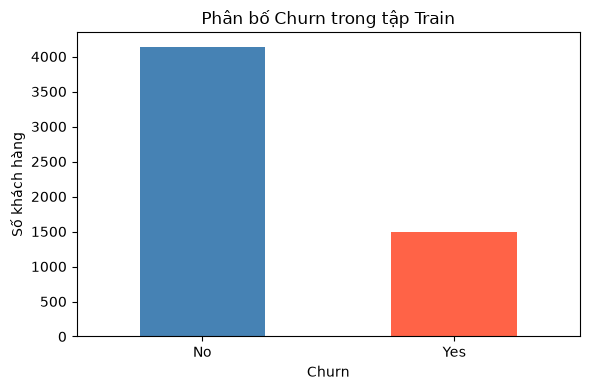

In [6]:
import matplotlib.pyplot as plt

counts = df[TARGET_COLUMN].value_counts().reindex(["No", "Yes"])
rates = counts.div(len(df)).mul(100).round(2)

display(pd.DataFrame({
    "Số khách hàng": counts,
    "Tỷ lệ (%)": rates,
}))

ax = counts.plot.bar(
    color=["steelblue", "tomato"],
    figsize=(6, 4),
)
ax.set_title("Phân bố Churn trong tập Train")
ax.set_xlabel("Churn")
ax.set_ylabel("Số khách hàng")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Trong tập Train, 1.495 khách hàng rời bỏ dịch vụ, chiếm 26,54%; số khách hàng không rời bỏ là 4.139, chiếm 73,46%. Vì hai lớp có quy mô khác nhau, khi đánh giá mô hình cần xem thêm Recall và F1-score của lớp Churn=Yes, không chỉ Accuracy.

### 2.2. Phân tích Churn theo các biến phân loại (Categorical Features)
Khảo sát tỷ lệ khách hàng rời mạng theo từng nhóm thuộc tính định tính: Hợp đồng (Contract), Dịch vụ Internet (InternetService), Phương thức thanh toán (PaymentMethod), Dịch vụ hỗ trợ (TechSupport, OnlineSecurity), và Nhân khẩu học (SeniorCitizen, Partner, Dependents).

Số khách hàng theo loại hợp đồng:


Churn,No,Yes
Contract,,
Month-to-month,1776,1326
One year,1043,130
Two year,1320,39


Tỷ lệ Churn=Yes trong từng loại hợp đồng (%):


Contract
Two year           2.87
One year          11.08
Month-to-month    42.75
dtype: float64

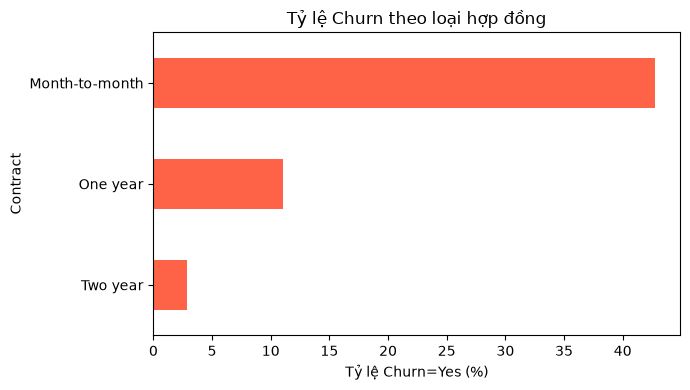

In [7]:
contract_table = pd.crosstab(
    df["Contract"],
    df[TARGET_COLUMN],
)

contract_yes_rate = (
    contract_table["Yes"]
    .div(contract_table.sum(axis=1))
    .mul(100)
    .sort_values()
)

print("Số khách hàng theo loại hợp đồng:")
display(contract_table)

print("Tỷ lệ Churn=Yes trong từng loại hợp đồng (%):")
display(contract_yes_rate.round(2))

ax = contract_yes_rate.plot.barh(
    figsize=(7, 4),
    color="tomato",
)
ax.set_title("Tỷ lệ Churn theo loại hợp đồng")
ax.set_xlabel("Tỷ lệ Churn=Yes (%)")
ax.set_ylabel("Contract")
plt.tight_layout()
plt.show()

Trong tập Train, khách hàng dùng hợp đồng theo tháng có tỷ lệ Churn=Yes là 42,75%, cao hơn hợp đồng một năm (11,08%) và hai năm (2,87%). Kết quả cho thấy loại hợp đồng có liên hệ với tình trạng rời bỏ trong dữ liệu này, nhưng riêng biểu đồ không chứng minh quan hệ nguyên nhân.

#### Hàm hỗ trợ trực quan hóa tỷ lệ Churn theo nhóm phân loại

Số khách hàng theo InternetService:


Churn,No,Yes
InternetService,,
DSL,1575,362
Fiber optic,1438,1045
No,1126,88


Tỷ lệ Churn=Yes trong từng nhóm (%):


InternetService
No              7.25
DSL            18.69
Fiber optic    42.09
dtype: float64

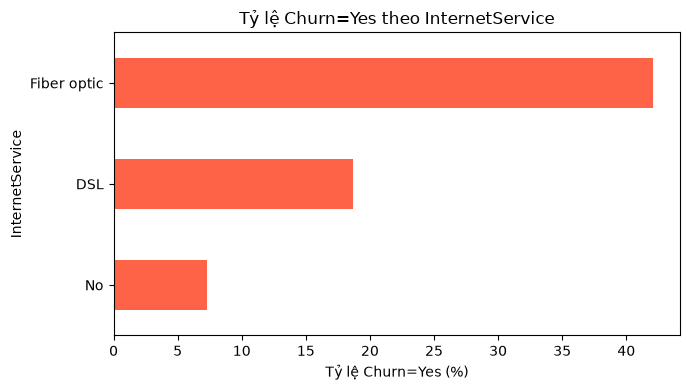

In [8]:
def plot_churn_by_category(column):
    table = pd.crosstab(df[column], df[TARGET_COLUMN])
    rate = (
        table["Yes"]
        .div(table.sum(axis=1))
        .mul(100)
        .sort_values()
    )

    print(f"Số khách hàng theo {column}:")
    display(table)

    print("Tỷ lệ Churn=Yes trong từng nhóm (%):")
    display(rate.round(2))

    ax = rate.plot.barh(figsize=(7, 4), color="tomato")
    ax.set_title(f"Tỷ lệ Churn=Yes theo {column}")
    ax.set_xlabel("Tỷ lệ Churn=Yes (%)")
    ax.set_ylabel(column)
    plt.tight_layout()
    plt.show()

plot_churn_by_category("InternetService")

Trong tập Train, nhóm dùng Fiber optic có tỷ lệ Churn=Yes là 42,09%, cao hơn nhóm DSL (18,69%) và nhóm không dùng Internet (7,25%). Đây là sự khác biệt quan sát được giữa các nhóm dịch vụ; biểu đồ chưa cho biết nguyên nhân của sự khác biệt đó.

#### Tỷ lệ Churn theo Phương thức thanh toán (PaymentMethod)

Số khách hàng theo PaymentMethod:


Churn,No,Yes
PaymentMethod,,
Bank transfer (automatic),1043,201
Credit card (automatic),1032,181
Electronic check,1026,865
Mailed check,1038,248


Tỷ lệ Churn=Yes trong từng nhóm (%):


PaymentMethod
Credit card (automatic)      14.92
Bank transfer (automatic)    16.16
Mailed check                 19.28
Electronic check             45.74
dtype: float64

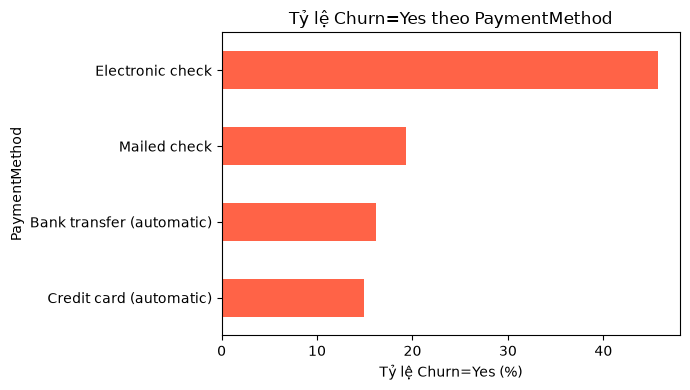

In [9]:
plot_churn_by_category("PaymentMethod")

Trong tập Train, khách hàng thanh toán bằng Electronic check có tỷ lệ Churn=Yes cao nhất, 45,74%. Các nhóm Mailed check, Bank transfer (automatic) và Credit card (automatic) lần lượt có tỷ lệ 19,28%, 16,16% và 14,92%. Đây là mối liên hệ trong dữ liệu, chưa chứng minh phương thức thanh toán là nguyên nhân gây rời bỏ.

#### Tỷ lệ Churn theo Dịch vụ hỗ trợ kỹ thuật (TechSupport)

Số khách hàng theo TechSupport:


Churn,No,Yes
TechSupport,,
No,1614,1157
No internet service,1126,88
Yes,1399,250


Tỷ lệ Churn=Yes trong từng nhóm (%):


TechSupport
No internet service     7.25
Yes                    15.16
No                     41.75
dtype: float64

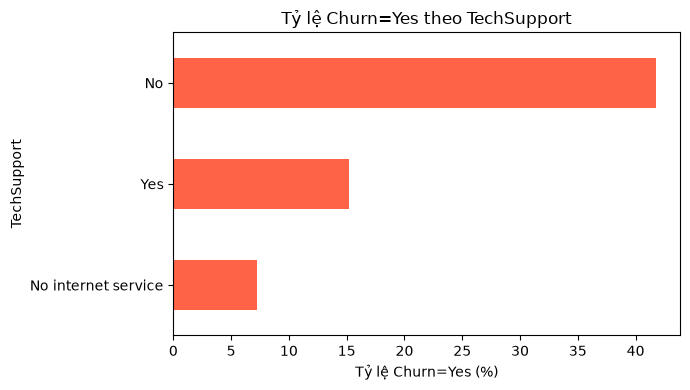

In [10]:
plot_churn_by_category("TechSupport")

Trong tập Train, nhóm dùng Internet nhưng không có TechSupport có tỷ lệ Churn=Yes là 41,75%, cao hơn nhóm có TechSupport (15,16%). Nhóm “No internet service” có tỷ lệ 7,25% và cần được xem là một nhóm riêng; các tỷ lệ này cho thấy mối liên hệ, chưa chứng minh hỗ trợ kỹ thuật trực tiếp làm thay đổi Churn.

#### Tỷ lệ Churn theo Dịch vụ bảo mật trực tuyến (OnlineSecurity)

Số khách hàng theo OnlineSecurity:


Churn,No,Yes
OnlineSecurity,,
No,1624,1173
No internet service,1126,88
Yes,1389,234


Tỷ lệ Churn=Yes trong từng nhóm (%):


OnlineSecurity
No internet service     7.25
Yes                    14.42
No                     41.94
dtype: float64

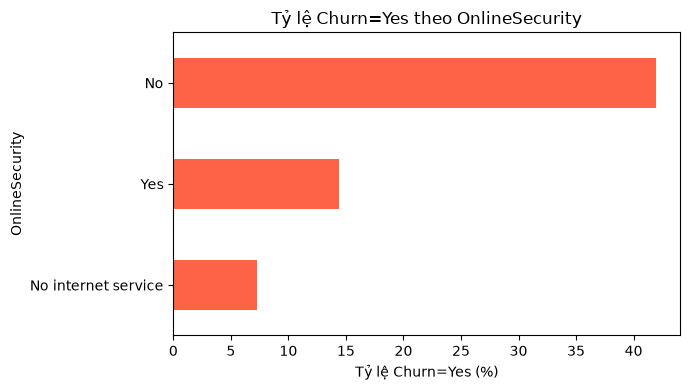

In [11]:
plot_churn_by_category("OnlineSecurity")

Trong tập Train, nhóm dùng Internet nhưng không có OnlineSecurity có tỷ lệ Churn=Yes là 41,94%, cao hơn nhóm có OnlineSecurity (14,42%). Nhóm “No internet service” có tỷ lệ 7,25% và được xem riêng; biểu đồ cho thấy mối liên hệ giữa các nhóm, chưa chứng minh quan hệ nguyên nhân.

#### Tỷ lệ Churn theo Người cao tuổi (SeniorCitizen)

Số khách hàng theo SeniorCitizen:


Churn,No,Yes
SeniorCitizen,,
0,3597,1117
1,542,378


Tỷ lệ Churn=Yes trong từng nhóm (%):


SeniorCitizen
0    23.70
1    41.09
dtype: float64

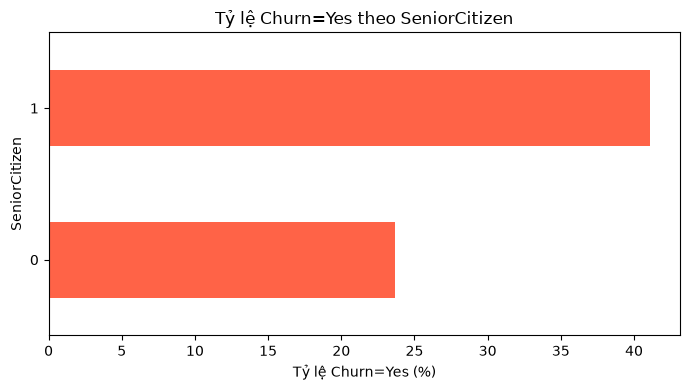

In [12]:
plot_churn_by_category("SeniorCitizen")

Trong tập Train, nhóm SeniorCitizen=1 có tỷ lệ Churn=Yes là 41,09%, cao hơn nhóm SeniorCitizen=0 (23,70%). Dữ liệu cho thấy tình trạng SeniorCitizen có liên hệ với Churn, nhưng biểu đồ này không chứng minh đây là nguyên nhân trực tiếp.

#### Tỷ lệ Churn theo Tình trạng có bạn đời (Partner)

Số khách hàng theo Partner:


Churn,No,Yes
Partner,,
No,1953,952
Yes,2186,543


Tỷ lệ Churn=Yes trong từng nhóm (%):


Partner
Yes    19.90
No     32.77
dtype: float64

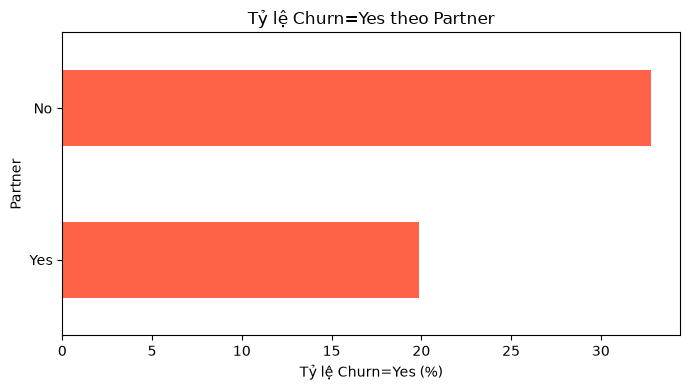

In [13]:
plot_churn_by_category("Partner")

Trong tập Train, khách hàng không có Partner có tỷ lệ Churn=Yes là 32,77%, cao hơn nhóm có Partner (19,90%). Đây là khác biệt quan sát được giữa hai nhóm; biểu đồ không chứng minh tình trạng Partner trực tiếp gây ra Churn.

#### Tỷ lệ Churn theo Tình trạng có người phụ thuộc (Dependents)

Số khách hàng theo Dependents:


Churn,No,Yes
Dependents,,
No,2715,1240
Yes,1424,255


Tỷ lệ Churn=Yes trong từng nhóm (%):


Dependents
Yes    15.19
No     31.35
dtype: float64

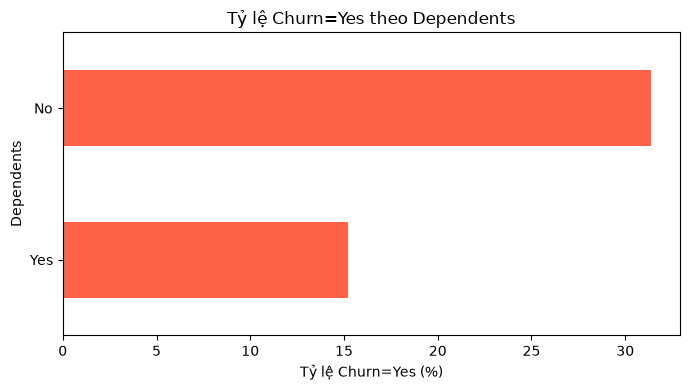

In [14]:
plot_churn_by_category("Dependents")

Trong tập Train, khách hàng không có người phụ thuộc có tỷ lệ Churn=Yes là 31,35%, cao hơn nhóm có người phụ thuộc (15,19%). Kết quả cho thấy Dependents có liên hệ với Churn trong dữ liệu, nhưng chưa chứng minh đây là nguyên nhân trực tiếp.

### 2.3. Phân tích Churn theo các biến định lượng (Numerical Features)
Khảo sát phân phối mật độ và trung vị của 3 biến số chính: thời gian sử dụng dịch vụ (`tenure`), cước hàng tháng (`MonthlyCharges`) và tổng cước lũy kế (`TotalCharges`) đối với từng nhóm khách hàng.

Trung vị tenure theo Churn:


Churn
No     38.0
Yes    10.0
Name: tenure, dtype: float64

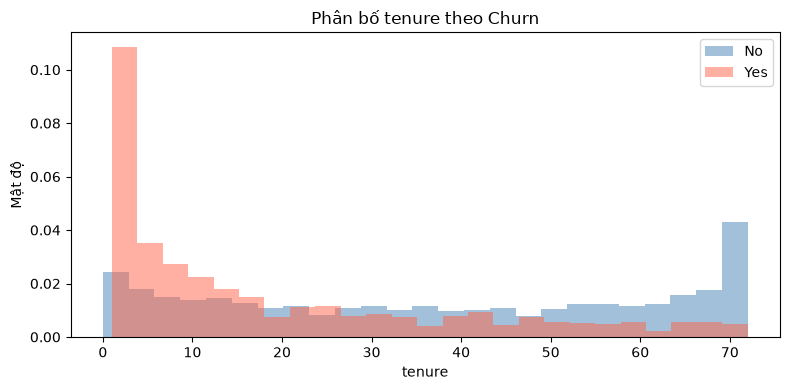

In [15]:
def plot_numeric_by_churn(column):
    print(f"Trung vị {column} theo Churn:")
    display(df.groupby(TARGET_COLUMN)[column].median().round(2))

    plt.figure(figsize=(8, 4))

    for label, color in [("No", "steelblue"), ("Yes", "tomato")]:
        values = df.loc[
            df[TARGET_COLUMN] == label,
            column,
        ].dropna()

        plt.hist(
            values,
            bins=25,
            alpha=0.5,
            density=True,
            label=label,
            color=color,
        )

    plt.title(f"Phân bố {column} theo Churn")
    plt.xlabel(column)
    plt.ylabel("Mật độ")
    plt.legend()
    plt.tight_layout()
    plt.show()

plot_numeric_by_churn("tenure")

Trong tập Train, trung vị thời gian sử dụng dịch vụ của nhóm Churn=Yes là 10 tháng, thấp hơn nhóm Churn=No (38 tháng). Biểu đồ cho thấy nhóm rời bỏ tập trung nhiều hơn ở thời gian sử dụng ngắn; đây là mối liên hệ quan sát được, chưa chứng minh thời gian sử dụng là nguyên nhân trực tiếp.

#### Phân bố Cước phí hàng tháng (MonthlyCharges) theo Churn

Trung vị MonthlyCharges theo Churn:


Churn
No     64.40
Yes    79.95
Name: MonthlyCharges, dtype: float64

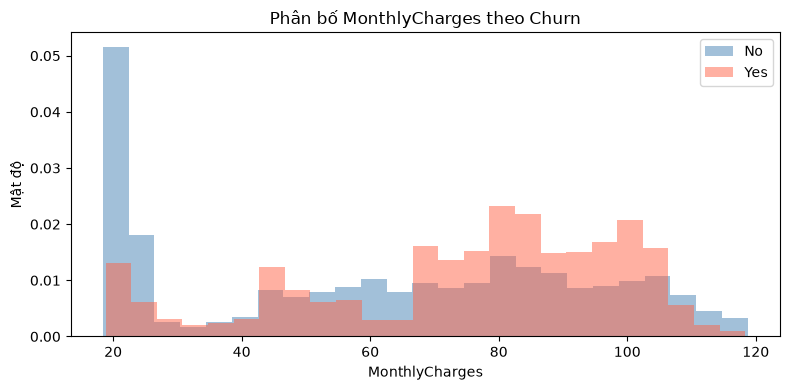

In [16]:
plot_numeric_by_churn("MonthlyCharges")

Trong tập Train, trung vị MonthlyCharges của nhóm Churn=Yes là 79,95, cao hơn nhóm Churn=No (64,40). Biểu đồ cho thấy nhóm rời bỏ tập trung nhiều hơn ở mức phí hằng tháng cao, nhưng hai nhóm vẫn có vùng phân bố chồng lấn.

#### Phân bố Tổng cước tích lũy (TotalCharges) theo Churn

Trung vị TotalCharges theo Churn:


Churn
No     1691.9
Yes     740.3
Name: TotalCharges, dtype: float64

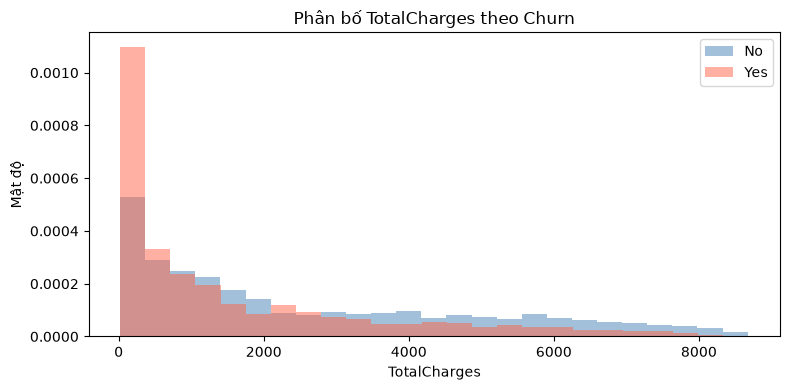

In [17]:
plot_numeric_by_churn("TotalCharges")

Trong tập Train, trung vị TotalCharges của nhóm Churn=Yes là 740,3, thấp hơn nhóm Churn=No (1.691,9). Nhóm rời bỏ cũng có thời gian sử dụng ngắn hơn theo biểu đồ tenure, nên tổng phí tích lũy thấp có thể liên quan đến thời gian sử dụng; biểu đồ này không chứng minh tổng phí thấp gây ra Churn.

## 3. Xây dựng Pipeline Tiền xử lý Luồng A (Pipeline cơ bản)
Theo yêu cầu đề bài, Luồng A là pipeline cơ bản đóng vai trò chuẩn hóa toàn diện:
- Tách riêng danh sách cột định lượng (`numeric_columns`) và cột định tính (`categorical_columns`).
- Áp dụng các phương pháp xử lý dữ liệu thiếu và mã hóa/chuẩn hóa phù hợp cho từng loại cột.

In [18]:
numeric_columns = X_train.select_dtypes(
    include="number"
).columns.tolist()

categorical_columns = X_train.select_dtypes(
    exclude="number"
).columns.tolist()

print("Cột số:", numeric_columns)
print("Số cột số:", len(numeric_columns))
print("Cột phân loại:", categorical_columns)
print("Số cột phân loại:", len(categorical_columns))

assert len(numeric_columns) + len(categorical_columns) == X_train.shape[1]

Cột số: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
Số cột số: 4
Cột phân loại: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']
Số cột phân loại: 15


### 3.1. Thiết kế bộ tiền xử lý với ColumnTransformer
- **Nhánh số (numeric_pipeline):** Điền khuyết bằng trung vị (`SimpleImputer(strategy='median')`) để tránh ảnh hưởng của ngoại lệ, sau đó chuẩn hóa thang đo bằng `StandardScaler()`.
- **Nhánh phân loại (categorical_pipeline):** Điền khuyết bằng giá trị thường gặp nhất (`SimpleImputer(strategy='most_frequent')`), sau đó mã hóa nhị phân bằng `OneHotEncoder(handle_unknown='ignore')` để xử lý an toàn các giá trị mới khi suy luận.
- **ColumnTransformer:** Ghép hai nhánh xử lý thành một pipeline duy nhất `preprocessor_A`.

In [19]:
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

print(numeric_pipeline)

Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('scaler', StandardScaler())])


In [20]:
from sklearn.preprocessing import OneHotEncoder

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    (
        "onehot",
        OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False,
        ),
    ),
])

print(categorical_pipeline)

Pipeline(steps=[('imputer', SimpleImputer(strategy='most_frequent')),
                ('onehot',
                 OneHotEncoder(handle_unknown='ignore', sparse_output=False))])


In [21]:
from sklearn.compose import ColumnTransformer

preprocessor_A = ColumnTransformer(
    transformers=[
        ("num", numeric_pipeline, numeric_columns),
        ("cat", categorical_pipeline, categorical_columns),
    ],
    remainder="drop",
).set_output(transform="pandas")

print("Đã tạo:", type(preprocessor_A).__name__)
print("Số cột đầu vào:", len(numeric_columns) + len(categorical_columns))

Đã tạo: ColumnTransformer
Số cột đầu vào: 19


### 3.2. Huấn luyện bộ tiền xử lý trên tập Train và chuyển đổi tập Test (Chống Data Leakage)
**Quy tắc phòng chống rò rỉ dữ liệu:**
- `preprocessor_A.fit_transform(X_train)`: Học các tham số thống kê (trung vị, trung bình, độ lệch chuẩn, danh sách danh mục One-Hot) **CHỈ từ tập Train**.
- `preprocessor_A.transform(X_test)`: Áp dụng trực tiếp các tham số đã học lên tập Test, tuyệt đối không tính lại tham số trên Test.

In [22]:
X_train_A = preprocessor_A.fit_transform(X_train)
X_test_A = preprocessor_A.transform(X_test)

print("X_train_A:", X_train_A.shape)
print("X_test_A:", X_test_A.shape)
print("Kiểu kết quả:", type(X_train_A).__name__)

X_train_A: (5634, 45)
X_test_A: (1409, 45)
Kiểu kết quả: DataFrame


In [23]:
assert len(X_train_A) == len(y_train)
assert len(X_test_A) == len(y_test)
assert X_train_A.columns.equals(X_test_A.columns)

assert X_train_A.isna().sum().sum() == 0
assert X_test_A.isna().sum().sum() == 0

assert X_train_A.select_dtypes(exclude="number").empty
assert X_test_A.select_dtypes(exclude="number").empty

print("Tất cả kiểm tra Luồng A: đạt")
print("Một số tên cột sau xử lý:")
print(X_train_A.columns[:12].tolist())

Tất cả kiểm tra Luồng A: đạt
Một số tên cột sau xử lý:
['num__SeniorCitizen', 'num__tenure', 'num__MonthlyCharges', 'num__TotalCharges', 'cat__gender_Female', 'cat__gender_Male', 'cat__Partner_No', 'cat__Partner_Yes', 'cat__Dependents_No', 'cat__Dependents_Yes', 'cat__PhoneService_No', 'cat__PhoneService_Yes']


In [24]:
assert X_train_A.index.equals(X_train.index)
assert X_test_A.index.equals(X_test.index)

X_train_A.to_csv(
    PROCESSED_DIR / "X_train_A.csv",
    index=False,
)
X_test_A.to_csv(
    PROCESSED_DIR / "X_test_A.csv",
    index=False,
)

print("Đã lưu:", PROCESSED_DIR / "X_train_A.csv")
print("Đã lưu:", PROCESSED_DIR / "X_test_A.csv")

Đã lưu: C:\Users\admin\Desktop\Subject\Nhap_Mon_Hoc_May\BTL\BTL_New_Version\BTL_Nhap_Mon_Hoc_May_NHOM4\data\processed\X_train_A.csv
Đã lưu: C:\Users\admin\Desktop\Subject\Nhap_Mon_Hoc_May\BTL\BTL_New_Version\BTL_Nhap_Mon_Hoc_May_NHOM4\data\processed\X_test_A.csv


### 3.3. Lưu trữ dữ liệu Luồng A và lưu mô hình tiền xử lý preprocessor_A.pkl
Lưu dữ liệu đầu ra `X_train_A.csv`, `X_test_A.csv` vào `data/processed/` và lưu mô hình tiền xử lý `preprocessor_A.pkl` vào thư mục `models/` để bàn giao cho Đức và Hải huấn luyện mô hình.

In [25]:
import joblib

MODELS_DIR = PROJECT_ROOT / "models"
MODELS_DIR.mkdir(parents=True, exist_ok=True)

MODEL_PATH = MODELS_DIR / "preprocessor_A.pkl"
joblib.dump(preprocessor_A, MODEL_PATH)

print("Đã lưu preprocessor:", MODEL_PATH)

Đã lưu preprocessor: C:\Users\admin\Desktop\Subject\Nhap_Mon_Hoc_May\BTL\BTL_New_Version\BTL_Nhap_Mon_Hoc_May_NHOM4\models\preprocessor_A.pkl


### 3.4. Kiểm tra và xác nhận tính toàn vẹn của kết quả Luồng A
Kiểm tra lại kích thước dòng/cột của các file đã lưu và kiểm thử chức năng biến đổi của đối tượng `preprocessor_A.pkl` khi tải lại từ đĩa.

In [26]:
expected_files = {
    "X_train_raw.csv": (5634, 19),
    "X_test_raw.csv": (1409, 19),
    "X_train_A.csv": (5634, 45),
    "X_test_A.csv": (1409, 45),
    "y_train.csv": (5634, 1),
    "y_test.csv": (1409, 1),
}

for filename, expected_shape in expected_files.items():
    saved = pd.read_csv(PROCESSED_DIR / filename)
    assert saved.shape == expected_shape, filename
    assert not any(
        column.startswith("Unnamed:")
        for column in saved.columns
    ), filename
    print(filename, saved.shape, "— đạt")

assert MODEL_PATH.exists()
print("preprocessor_A.pkl — đạt")

X_train_raw.csv (5634, 19) — đạt
X_test_raw.csv (1409, 19) — đạt
X_train_A.csv (5634, 45) — đạt
X_test_A.csv (1409, 45) — đạt
y_train.csv (5634, 1) — đạt
y_test.csv (1409, 1) — đạt
preprocessor_A.pkl — đạt


In [27]:
loaded_preprocessor = joblib.load(MODEL_PATH)

first_three_rows = loaded_preprocessor.transform(X_test.head(3))

pd.testing.assert_frame_equal(
    first_three_rows,
    X_test_A.head(3),
)

print("Tải lại preprocessor và biến đổi 3 dòng Test: đạt")
print("Kích thước kết quả:", first_three_rows.shape)

Tải lại preprocessor và biến đổi 3 dòng Test: đạt
Kích thước kết quả: (3, 45)
